## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

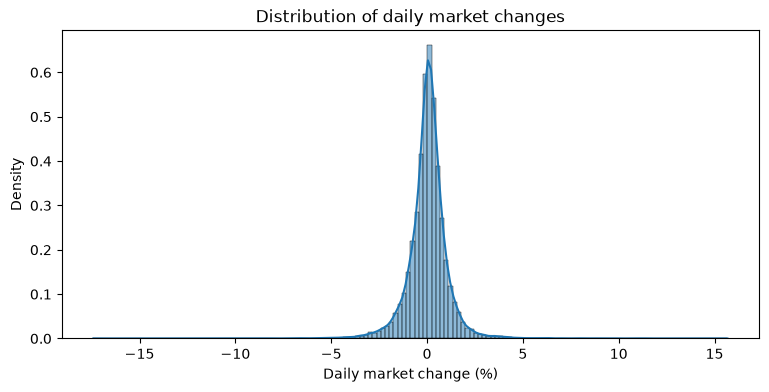

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

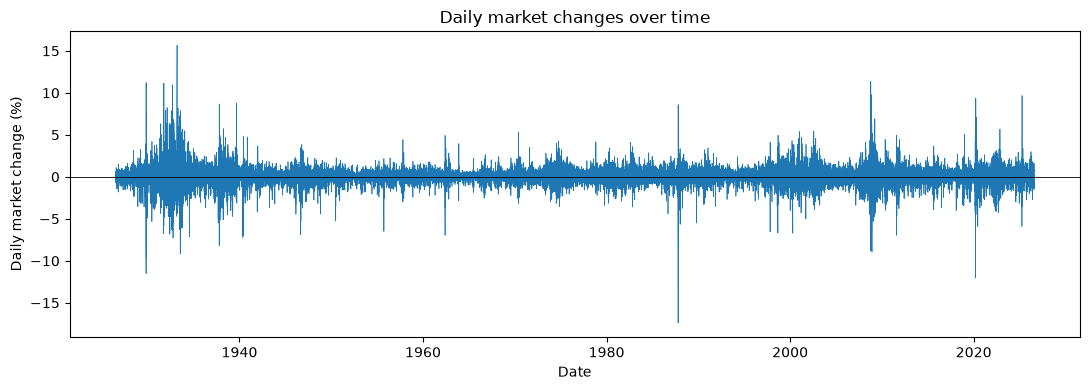

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# Current and next trading day's return
df['r_t'] = df['market_return_pct']
df['r_tp1'] = df['market_return_pct'].shift(-1)   # last row has no next day -> NaN

# Two states: Up (> 0) vs Down/flat (<= 0); keep NaN for the last row
df['up_t'] = np.where(df['r_t'] > 0, 'Up', 'Down/flat')
df['up_tp1'] = np.where(df['r_tp1'] > 0, 'Up', 'Down/flat')
df.loc[df['r_tp1'].isna(), 'up_tp1'] = np.nan

pairs2 = df.dropna(subset=['up_tp1'])
print("Raw counts (rows = today, columns = next trading day):")
pd.crosstab(pairs2['up_t'], pairs2['up_tp1'])

Raw counts (rows = today, columns = next trading day):


up_tp1,Down/flat,Up
up_t,,
Down/flat,5909,5999
Up,5999,8388


#### Joint PMF with marginals
The whole table sums to 1. The `All` column is the marginal of today's state; the `All` row is the marginal of the next day's state.

up_tp1,Down/flat,Up,All
up_t,,,
Down/flat,0.2247,0.2281,0.4529
Up,0.2281,0.3190,0.5471
All,0.4529,0.5471,1.0000


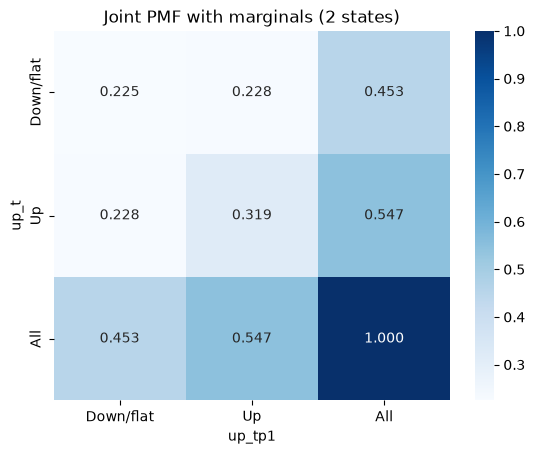

In [5]:
joint2 = pd.crosstab(pairs2['up_t'], pairs2['up_tp1'], normalize=True, margins=True)
display(joint2.round(4))
sns.heatmap(joint2, annot=True, fmt='.3f', cmap='Blues').set(title='Joint PMF with marginals (2 states)')
plt.show()

#### Conditional PMF
Each row sums to 1: $\Pr(Y_{t+1}=j \mid Y_t=i)$.

up_tp1,Down/flat,Up
up_t,,
Down/flat,0.4962,0.5038
Up,0.4170,0.5830


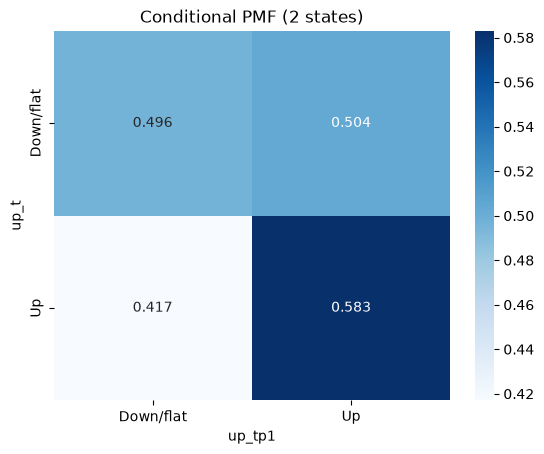

In [6]:
cond2 = pd.crosstab(pairs2['up_t'], pairs2['up_tp1'], normalize='index')
display(cond2.round(4))
sns.heatmap(cond2, annot=True, fmt='.3f', cmap='Blues').set(title='Conditional PMF (2 states)')
plt.show()

**Answer (Are up transitions more or less common than down transitions? Are you more likely to move to an Up day from a Down or an Up day?):** *your answer here*
- Yes up transitions are more common, we see about that tomorrow is about 55% up and 45% down. We also see that up up is the most common transition.
- You are more likely to move to an Up day from an Up day over a down day (.58 for up vs .50 for down). After a down day, you are more like for another down day (.50 down vs .43 up)

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
labels5 = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
bins5 = [-np.inf, -1, -0.1, 0.1, 1, np.inf]          # right-closed: each bin includes its upper endpoint

df['bin5'] = pd.cut(df['market_return_pct'], bins=bins5, labels=labels5)
df['y_t'] = df['bin5']
df['y_tp1'] = df['bin5'].shift(-1)

counts5 = df['y_t'].value_counts().reindex(labels5)
counts5.to_frame('days').assign(share=lambda d: (d['days'] / d['days'].sum()).round(4))

,days,share
y_t,,
Large loss,2759,0.1049
Small loss,7452,0.2834
Near zero,3441,0.1309
Small gain,9785,0.3721
Large gain,2859,0.1087


**Answer (How many days fall into each bin? Which are most / least common?):** *your answer here*
- Large loss: 2,759 days, Small loss: 7,452, Near zero: 3,441, Small gain: 9,785, Large gain: 2,859.
- The most common is a small gain at 37% and the least common is a large loss at .1049. 

#### Joint PMF and marginals (5 states)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.0213,0.0272,0.0091,0.0278,0.0195,0.1049
Small loss,0.0354,0.0886,0.0342,0.0978,0.0274,0.2834
Near zero,0.0093,0.0420,0.0210,0.0493,0.0093,0.1309
Small gain,0.0250,0.1001,0.0550,0.1594,0.0326,0.3721
Large gain,0.0138,0.0255,0.0116,0.0378,0.0199,0.1087
All,0.1049,0.2834,0.1308,0.3721,0.1087,1.0000


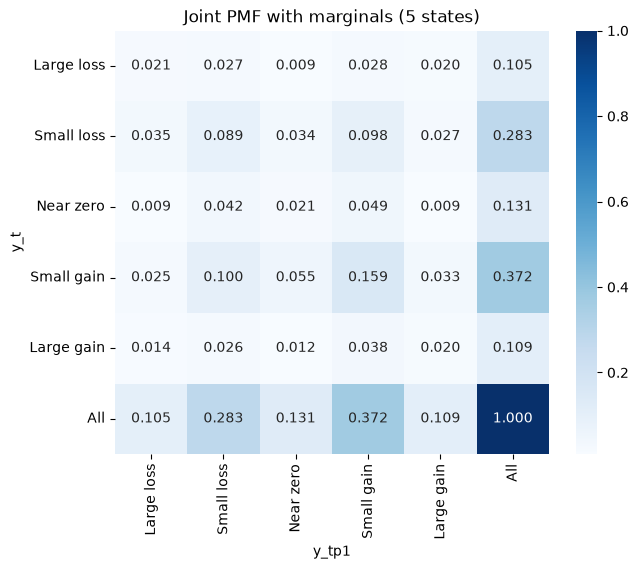

y_t         y_tp1     
Small gain  Small gain    0.1594
            Small loss    0.1001
Small loss  Small gain    0.0978
            Small loss    0.0886
Small gain  Near zero     0.0550
Near zero   Small gain    0.0493
dtype: float64

In [8]:
pairs5 = df.dropna(subset=['y_tp1'])
joint5 = pd.crosstab(pairs5['y_t'], pairs5['y_tp1'], normalize=True, margins=True)
display(joint5.round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(joint5, annot=True, fmt='.3f', cmap='Blues', ax=ax).set(title='Joint PMF with marginals (5 states)')
plt.show()

# Most likely transitions, ranked
joint5_only = pd.crosstab(pairs5['y_t'], pairs5['y_tp1'], normalize=True)
joint5_only.stack().sort_values(ascending=False).head(6).round(4)

**Answer (Which transitions are most likely to occur?):** *your answer here*
- The top two most likely transitions are small gain to small gain at 16% and small gain to small loss at 10%, everything else is below 10%. 

#### Conditional PMF (5 states)
Compare each row to the uniform PMF (0.2 per column).

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.2033,0.2592,0.0863,0.2650,0.1863
Small loss,0.1251,0.3128,0.1205,0.3450,0.0966
Near zero,0.0712,0.3208,0.1601,0.3769,0.0709
Small gain,0.0672,0.2689,0.1479,0.4285,0.0876
Large gain,0.1273,0.2347,0.1070,0.3477,0.1833


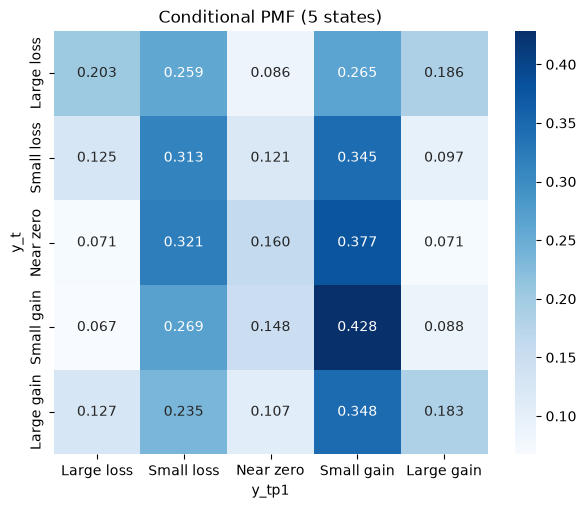

,two most likely next states
y_t,
Large loss,"Small gain (0.26), Small loss (0.26)"
Small loss,"Small gain (0.35), Small loss (0.31)"
Near zero,"Small gain (0.38), Small loss (0.32)"
Small gain,"Small gain (0.43), Small loss (0.27)"
Large gain,"Small gain (0.35), Small loss (0.23)"


In [9]:
cond5 = pd.crosstab(pairs5['y_t'], pairs5['y_tp1'], normalize='index')
display(cond5.round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cond5, annot=True, fmt='.3f', cmap='Blues', ax=ax).set(title='Conditional PMF (5 states)')
plt.show()

# Two most likely next states for each current state
top2 = cond5.apply(lambda row: ', '.join(f"{k} ({v:.2f})" for k, v in row.nlargest(2).items()), axis=1)
top2.to_frame('two most likely next states')

In [10]:
# How far is each row from uniform (0.2 each)? Total variation distance: 0 = exactly uniform, 1 = completely predictable
tv = (cond5 - 0.2).abs().sum(axis=1) / 2
tv.round(3).to_frame('TV distance from uniform')

,TV distance from uniform
y_t,
Large loss,0.127
Small loss,0.258
Near zero,0.298
Small gain,0.297
Large gain,0.182


**Answer (For each state, which two next states are most likely? How close is each row to uniform? Is the next state easy or hard to predict?):** *your answer here*
- For every state, the two next states that are most likely are a small gain and a small loss in that order.
- No row is exactly uniform, but none are far from it. In most rows, a single high value, usually Small gain, is what pulls the row away from uniform.
- I would say its relatively hard to predict the next state because the highest probability is only 43%. Now that being said these are just the numbers because there is a lot of information available that can aid in prediction (more categorical variables like the company success etc.)

#### Conditional expectation of tomorrow's return

In [11]:
cond_exp5 = df.groupby('y_t', observed=False)['r_tp1'].describe()
cond_exp5

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


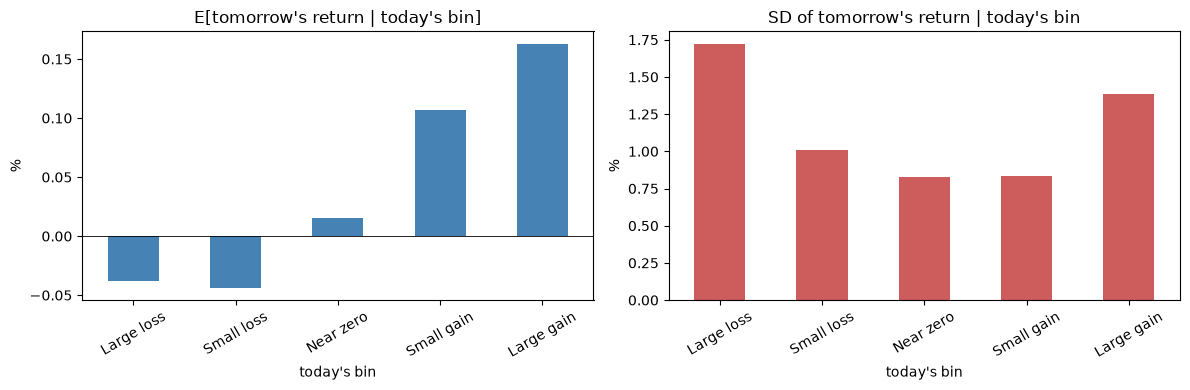

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cond_exp5['mean'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].axhline(0, color='black', lw=0.6)
axes[0].set(title="E[tomorrow's return | today's bin]", ylabel='%', xlabel="today's bin")
cond_exp5['std'].plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set(title="SD of tomorrow's return | today's bin", ylabel='%', xlabel="today's bin")
for ax in axes: ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Answer (Expected return tomorrow for each state? How do min/max vary? Which states have the highest SD? What patterns in volatility do you see?):** *your answer here*
- Tomorrow's expected return is −0.04% after a Large loss, −0.04% after a Small loss, +0.02% after Near zero, +0.11% after a Small gain, and +0.16% after a Large gain.
- The min and max are most extreme after large moves (−17.41 after a Large loss, +15.67 after a Large gain).
- Large loss and Large gain have the highest standard deviations of 1.72 and 1.38 respectively.
- Volatility is higher after large moves in either direction, so big swings tend to be followed by more big swings. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [13]:
N_BINS = 21
df['y_t'] = pd.qcut(df['market_return_pct'], q=N_BINS, labels=False)   # bins 0 (biggest losses) ... 20 (biggest gains)
df['y_tp1'] = df['y_t'].shift(-1)

pairs21 = df.dropna(subset=['y_tp1']).astype({'y_tp1': int})

# Return range covered by each bin (roughly equal number of days in each)
pd.qcut(df['market_return_pct'], q=N_BINS).value_counts().sort_index().to_frame('days')

,days
market_return_pct,
"(-17.411, -1.61]",1255
"(-1.61, -1.07]",1253
"(-1.07, -0.78]",1286
"(-0.78, -0.57]",1280
"(-0.57, -0.42]",1230
"(-0.42, -0.3]",1226
"(-0.3, -0.19]",1371
"(-0.19, -0.11]",1206
"(-0.11, -0.03]",1198


#### Joint PMF (21 bins)

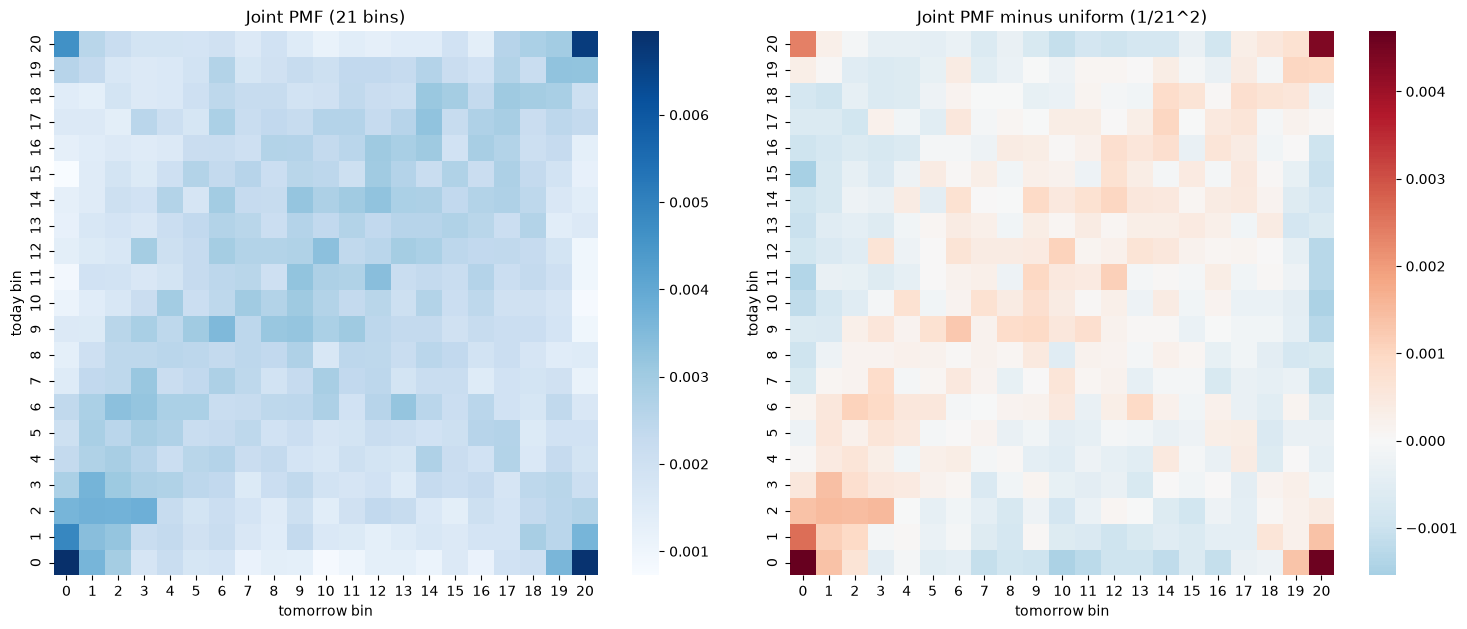

In [14]:
joint21 = pd.crosstab(pairs21['y_t'], pairs21['y_tp1'], normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(joint21, cmap='Blues', ax=axes[0], square=True).set(
    title='Joint PMF (21 bins)', xlabel='tomorrow bin', ylabel='today bin')
sns.heatmap(joint21 - 1 / N_BINS**2, cmap='RdBu_r', center=0, ax=axes[1], square=True).set(
    title='Joint PMF minus uniform (1/21^2)', xlabel='tomorrow bin', ylabel='today bin')
for ax in axes: ax.invert_yaxis()   # put bin 0 at the bottom, like a plot axis
plt.tight_layout(); plt.show()

**Answer (Any obvious patterns in the joint PMF? What shows up after subtracting the uniform PMF?):** *your answer here*
- We see that the raw joint PMF looks mostly uniform across the board, with the darkest spots in the corners. This suggests that very big days are also followed by big days in both directions.
- After we remove the uniform, the corners continue to stand out, the changes of a big move after another big move is two to three times more likely. After a normal day, a big move chances are very low. 

#### Conditional PMF (21 bins)

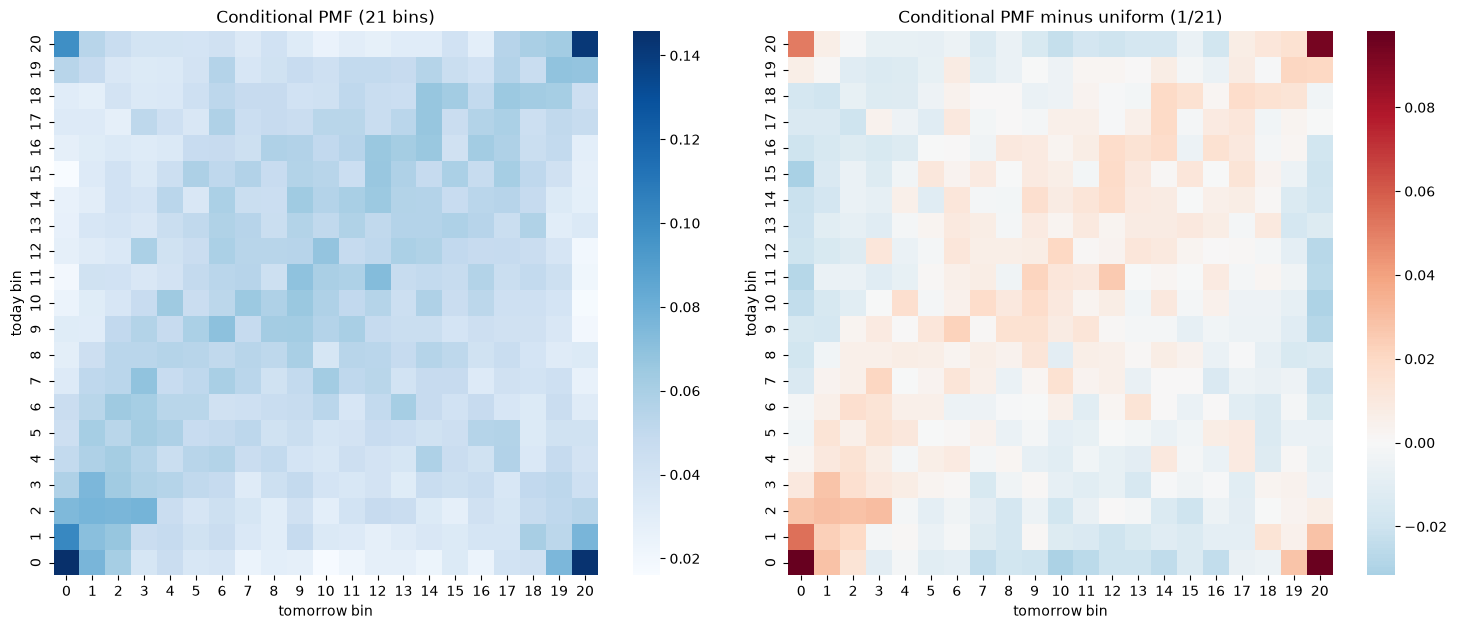

In [15]:
cond21 = pd.crosstab(pairs21['y_t'], pairs21['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cond21, cmap='Blues', ax=axes[0], square=True).set(
    title='Conditional PMF (21 bins)', xlabel='tomorrow bin', ylabel='today bin')
sns.heatmap(cond21 - 1 / N_BINS, cmap='RdBu_r', center=0, ax=axes[1], square=True).set(
    title='Conditional PMF minus uniform (1/21)', xlabel='tomorrow bin', ylabel='today bin')
for ax in axes: ax.invert_yaxis()
plt.tight_layout(); plt.show()

**Answer (Any obvious patterns in the conditional PMF? What shows up after subtracting 1/21?):** *your answer here*
- We see that the conditional PMF looks almost identical to the joint PMF, since every bin has about the same number of days. Most rows are close to uniform, with the darkest spots in the corners, which suggests that very big days are often followed by other big days in either direction.
- After we subtract the uniform, the corners still stand out: the chance of a big move after another big move is about three times more likely than chance. After a normal day, a big move is less likely than chance.

#### Next day's min, mean, max by bin

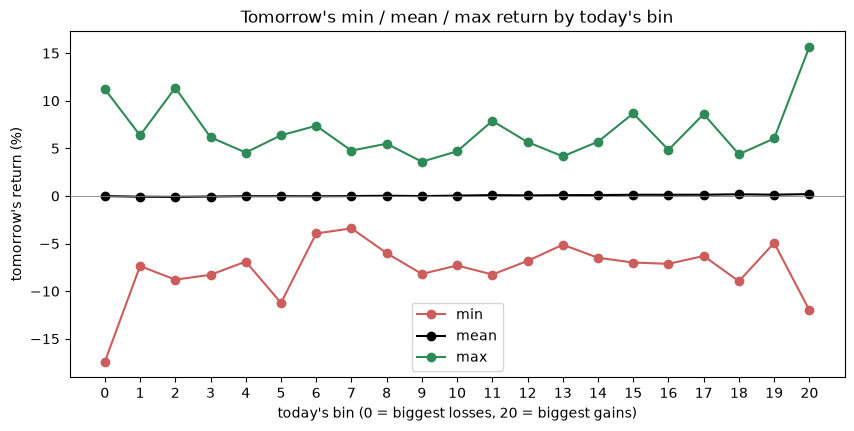

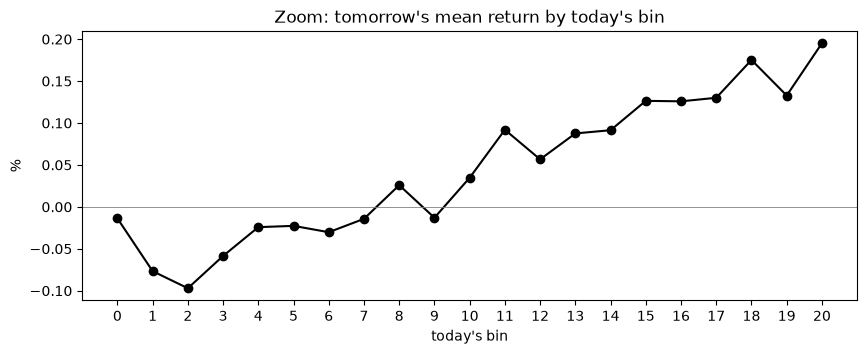

In [16]:
stats21 = df.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max', 'std'])

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, color in [('min', 'indianred'), ('mean', 'black'), ('max', 'seagreen')]:
    ax.plot(stats21.index, stats21[col], marker='o', color=color, label=col)
ax.axhline(0, color='gray', lw=0.6)
ax.set(xlabel="today's bin (0 = biggest losses, 20 = biggest gains)", ylabel="tomorrow's return (%)",
       title="Tomorrow's min / mean / max return by today's bin", xticks=range(N_BINS))
ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(stats21.index, stats21['mean'], marker='o', color='black')
ax.axhline(0, color='gray', lw=0.6)
ax.set(xlabel="today's bin", ylabel='%', title="Zoom: tomorrow's mean return by today's bin", xticks=range(N_BINS))
plt.show()

**Answer (Patterns in tomorrow's min / mean / max across bins?):** *your answer here*
- For the min, the lowest next days come after the biggest loss days (−17%) and the biggest gain days (−12%).
- For the max, the highest next days come after the biggest gain days (+16%) and the biggest loss days (+11%).
- For the mean, it stays close to zero, rising slightly from about −0.1% after loss days to +0.2% after gain days.

#### Next day's standard deviation by bin

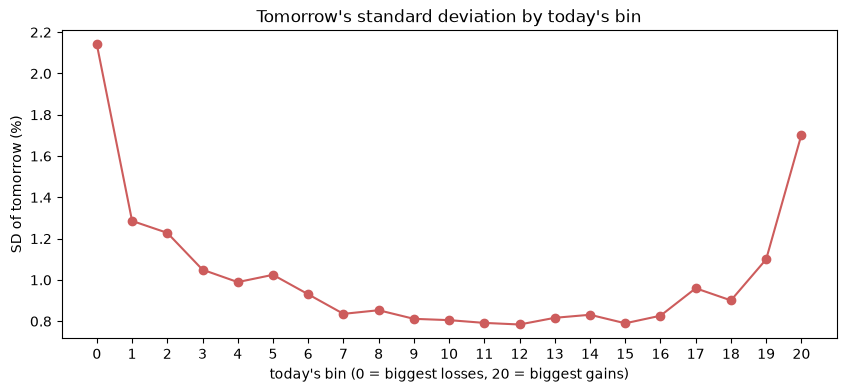

,min,mean,max,std
y_t,,,,
0,-17.41,-0.014,11.22,2.140
1,-7.36,-0.077,6.36,1.286
2,-8.79,-0.097,11.36,1.228
3,-8.28,-0.059,6.16,1.050
4,-6.89,-0.024,4.56,0.989
5,-11.23,-0.023,6.37,1.025
6,-3.94,-0.030,7.37,0.930
7,-3.40,-0.014,4.76,0.836
8,-6.00,0.026,5.49,0.853


In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stats21.index, stats21['std'], marker='o', color='indianred')
ax.set(xlabel="today's bin (0 = biggest losses, 20 = biggest gains)", ylabel='SD of tomorrow (%)',
       title="Tomorrow's standard deviation by today's bin", xticks=range(N_BINS))
plt.show()
stats21.round(3)

**Answer (Patterns in tomorrow's standard deviation across bins?):** *your answer here*
- After normal days, tomorrow's moves are small (standard deviation about 0.8). After the biggest loss or gain days, tomorrow's moves are much bigger (2.14 and 1.70).

**Answer (Overall: how easy is it to predict the market?):** *your answer here*
- The direction is hard to predict because tomorrow's average return is close to zero no matter what happened today. However, when the movement is after a big day, its easier to predict a bigger swing tomorrow.